# Matching model, step 1: zero-shot, then fine-tuned bi-encoder

Run cells **top to bottom, one at a time** on a **T4 GPU** (Runtime > Change runtime type).

Idea: instead of a classifier with 180 outputs, embed the sentence and each technique's description, and rank all techniques by similarity (**733** = all 737 ATT&CK v12 Enterprise labels minus 4 revoked ids whose description is identical to the active id that replaced them). Unseen techniques can then be predicted too.

| Cell | What it does |
|---|---|
| 1 | Paths, imports; downloads `ttp-desc-mappings.csv` if missing |
| 2 | Data, label space, metrics (paper-style micro P@1 / R@1, MRR@3) |
| 3 | Model + training code (defines only) |
| 4 | Zero-shot: no training at all |
| 5 | Fine-tune on TRAM train (about 20-30 min) |
| 6 | Results table vs the baselines |

Outputs go to `run_match_1`.

In [ ]:

# Cell 1 - setup, paths, imports
import os, ast, json, random, re, math, warnings, urllib.request
import numpy as np
import pandas as pd

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

DATA_DIR = "/content/drive/MyDrive/KDU/Thesis/Dataset"
OUT_ROOT = "/content/drive/MyDrive/KDU/Thesis/run_match_1"          # new folder for this experiment
os.makedirs(OUT_ROOT, exist_ok=True)

# Technique descriptions (737 ATT&CK v12 labels) come from the paper's repo. Download once if missing.
DESC_PATH = f"{DATA_DIR}/ttp-desc-mappings.csv"
if not os.path.exists(DESC_PATH):
    url = "https://raw.githubusercontent.com/tumeteor/mitre-ttp-mapping/main/datasets/ttp-desc-mappings.csv"
    urllib.request.urlretrieve(url, DESC_PATH)
    print("downloaded", DESC_PATH)

BASE_MODEL = "BAAI/bge-base-en-v1.5"      # embedding model (try "BAAI/bge-large-en-v1.5" later if memory allows)
print("OUT_ROOT =", OUT_ROOT)

Mounted at /content/drive
OUT_ROOT = /content/drive/MyDrive/KDU/Thesis/run_match_1


In [ ]:
# Cell 2 - data, label space (737 ATT&CK v12 Enterprise labels minus 4 revoked duplicate ids) and metrics
def load_split(name):
    df = pd.read_csv(f"{DATA_DIR}/tram_{name}.tsv", sep="\t").rename(columns={"text1": "text"})
    df["y"] = df["labels"].map(lambda x: sorted({s.lower() for s in ast.literal_eval(x)}))   # lowercase ids, de-duplicated
    return df[["text", "y"]]

train, dev, test = (load_split(s) for s in ("train", "dev", "test"))
train = train.drop_duplicates(subset=["text"]).reset_index(drop=True)
assert len(train) == 3468, len(train)

desc = pd.read_csv(DESC_PATH, sep="\t")
desc["ttp"] = desc["ttp"].str.lower().str.strip()
desc["description"] = (desc["description"].fillna("").str.replace(r"\s+", " ", regex=True)
                       .str.replace(r"\bcitation:\s*", "", regex=True).str.strip())   # drop the literal 'citation:' markers
desc = desc.drop_duplicates("ttp").reset_index(drop=True)

# Four REVOKED v12 technique ids have a description starts with the same text as to the active id that replaced them
# (checked against the official ATT&CK v12.0 data): t1060->t1547.001, t1107->t1070.004, t1151->t1036.006,
# t1188->t1090.003. They would tie with the correct label, so we remove the 4 old ids. Nothing else is removed.
drop = {"t1060", "t1107", "t1151", "t1188"}
assert drop <= set(desc["ttp"]), "drop list does not match the description file"
print("removed revoked duplicate ids:", sorted(drop))
desc = desc[~desc["ttp"].isin(drop)].reset_index(drop=True)
LABELS = desc["ttp"].tolist(); LABEL_TEXTS = desc["description"].tolist()
L = len(LABELS); lab2i = {l: i for i, l in enumerate(LABELS)}
print("labels in the matching space:", L)

def to_Y(df):
    Y = np.zeros((len(df), L), dtype=np.int64)
    missing = set()
    for i, ys in enumerate(df["y"]):
        for y in ys:
            if y in lab2i: Y[i, lab2i[y]] = 1
            else: missing.add(y)
    if missing: print("WARNING labels not in description file:", sorted(missing))
    return Y

Y_train, Y_dev, Y_test = to_Y(train), to_Y(dev), to_Y(test)
SEEN = Y_train.sum(axis=0) > 0                       # labels that occur in TRAM train
print(f"train={len(train)} dev={len(dev)} test={len(test)} | seen labels={SEEN.sum()} | "
      f"test gold labels={Y_test.sum()} (unseen-in-train: {int((Y_test.astype(bool) & ~SEEN[None, :]).sum())})")
assert (Y_train.sum(axis=1) > 0).all(), "a train row has no known label"

# parent technique of each label (for technique-level P@1)
PARENTS = [l.split(".")[0] for l in LABELS]
_up = sorted(set(PARENTS)); PAR_IDX = np.array([_up.index(p) for p in PARENTS])
PARMAT = np.zeros((L, len(_up))); PARMAT[np.arange(L), PAR_IDX] = 1

def rank_metrics(S, Y):
    """S: scores (rows x 737). Paper-style micro metrics over ALL gold labels (unseen ones included)."""
    n = len(S); top = np.argsort(-S, axis=1)[:, :5]
    hits = np.take_along_axis(Y, top, axis=1); total = Y.sum()
    h3 = hits[:, :3]
    first = np.where(h3.any(axis=1), h3.argmax(axis=1) + 1, np.inf)
    intop = np.zeros(Y.shape, dtype=bool); intop[np.arange(n)[:, None], top] = True
    gold = Y.astype(bool); un = gold & ~SEEN[None, :]; se = gold & SEEN[None, :]
    ypar = (Y @ PARMAT) > 0
    tech_hit = ypar[np.arange(n), PAR_IDX[top[:, 0]]]
    return {"P@1": float(hits[:, 0].mean()), "R@1": float(hits[:, 0].sum() / total),
            "MRR@3": float(np.mean(1.0 / first)), "R@5": float(hits.sum() / total),
            "tech_P@1": float(tech_hit.mean()),
            "seen_R@5": float((intop & se).sum() / max(se.sum(), 1)),
            "unseen_R@5": float((intop & un).sum() / max(un.sum(), 1)),
            "n_unseen_pairs": int(un.sum())}

removed revoked duplicate ids: ['t1060', 't1107', 't1151', 't1188']
labels in the matching space: 733
train=3468 dev=604 test=725 | seen labels=180 | test gold labels=851 (unseen-in-train: 10)


In [ ]:
# Cell 3 - bi-encoder model + training code
import torch, torch.nn as nn, torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

class Matcher(nn.Module):
    """One shared encoder for sentences and label descriptions; cosine similarity."""
    def __init__(self, name, pooling="cls"):
        super().__init__()
        self.enc = AutoModel.from_pretrained(name); self.pooling = pooling
    def forward(self, **enc):
        h = self.enc(**enc).last_hidden_state
        if self.pooling == "cls":
            v = h[:, 0]
        else:
            m = enc["attention_mask"].unsqueeze(-1).to(h.dtype); v = (h * m).sum(1) / m.sum(1).clamp(min=1)
        return F.normalize(v.float(), dim=-1)

def tok_batch(tok, texts, max_len):
    enc = tok(list(texts), padding=True, truncation=True, max_length=max_len, return_tensors="pt")
    return {k: v.to(device) for k, v in enc.items() if k in ("input_ids", "attention_mask", "token_type_ids")}

@torch.no_grad()
def embed_all(model, tok, texts, max_len, bs=64, amp=True):
    model.eval(); out = []
    for i in range(0, len(texts), bs):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp and device.type == "cuda"):
            out.append(model(**tok_batch(tok, texts[i:i + bs], max_len)).cpu())
    return torch.cat(out).numpy()

def score_split(model, tok, texts, label_emb, text_max_len=128):
    return embed_all(model, tok, list(texts), text_max_len) @ label_emb.T       # rows x labels cosine scores

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def run_eval(model, tok, label_max_len_eval=256):
    label_emb = embed_all(model, tok, LABEL_TEXTS, label_max_len_eval)
    S_dev = score_split(model, tok, dev["text"], label_emb); S_te = score_split(model, tok, test["text"], label_emb)
    return S_dev, S_te, rank_metrics(S_dev, Y_dev), rank_metrics(S_te, Y_test)

def train_matcher(model_name, out_dir, seed=42, epochs=8, patience=3, batch_size=16, lr=2e-5, n_neg=64,
                  scale=30.0, text_max_len=128, label_max_len_train=128, label_max_len_eval=256,
                  pooling="cls", use_amp=True, neg_pool="all"):
    set_seed(seed); os.makedirs(out_dir, exist_ok=True); rng = np.random.default_rng(seed)
    amp_on = use_amp and device.type == "cuda"
    tok = AutoTokenizer.from_pretrained(model_name)
    model = Matcher(model_name, pooling).to(device)
    N = len(train); texts = train["text"].tolist(); label_texts = np.array(LABEL_TEXTS, dtype=object)
    pos_lists = [np.where(Y_train[i])[0] for i in range(N)]
    pool = np.arange(L) if neg_pool == "all" else np.where(SEEN)[0]
    steps_per_epoch = math.ceil(N / batch_size)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps_per_epoch * epochs), steps_per_epoch * epochs)
    scaler = torch.amp.GradScaler(enabled=amp_on)
    print(f"[{model_name}] seed={seed} epochs<={epochs} bs={batch_size} lr={lr} n_neg={n_neg} scale={scale} neg_pool={neg_pool}")

    best, best_ep, best_state, bad, hist = -1.0, 0, None, 0, []
    for ep in range(1, epochs + 1):
        model.train(); perm = rng.permutation(N); tot = 0.0
        for b in range(0, N, batch_size):
            idx = perm[b:b + batch_size]
            gold_u = np.unique(np.concatenate([pos_lists[i] for i in idx]))
            cand = np.setdiff1d(pool, gold_u)
            negs = rng.choice(cand, size=min(n_neg, len(cand)), replace=False)
            U = np.concatenate([gold_u, negs])                                  # label set for this step
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_on):
                et = model(**tok_batch(tok, [texts[i] for i in idx], text_max_len))
                eu = model(**tok_batch(tok, label_texts[U].tolist(), label_max_len_train))
            S = (et @ eu.T) * scale                                             # batch x |U|, fp32
            pos = torch.tensor(Y_train[idx][:, U].astype(bool), device=device)
            neg_lse = torch.logsumexp(S.masked_fill(pos, -1e4), dim=1)          # log-sum-exp over negatives only
            rows = pos.nonzero()[:, 0]
            loss = F.softplus(neg_lse[rows] - S[pos]).mean()                    # = -log softmax of each positive vs negatives
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); tot += loss.item() * len(idx)
        _, _, md, _ = run_eval(model, tok, label_max_len_eval)
        hist.append({"epoch": ep, "train_loss": tot / N, **{f"dev_{k}": v for k, v in md.items()}})
        print(f"  epoch {ep:2d}: train_loss={tot / N:.4f} dev P@1={md['P@1']:.4f} MRR@3={md['MRR@3']:.4f} "
              f"R@5={md['R@5']:.4f} unseenR@5={md['unseen_R@5']:.3f}")
        if md["MRR@3"] > best:                                                  # select epoch by DEV MRR@3
            best, best_ep, bad = md["MRR@3"], ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                print(f"  early stop (no dev improvement for {patience} epochs)"); break

    model.load_state_dict(best_state)
    S_dev, S_te, md, mt = run_eval(model, tok, label_max_len_eval)
    np.save(f"{out_dir}/dev_scores.npy", S_dev); np.save(f"{out_dir}/test_scores.npy", S_te)
    json.dump({"model_name": model_name, "seed": seed, "best_epoch": best_ep, "dev": md, "test": mt, "history": hist,
               "config": dict(epochs=epochs, patience=patience, batch_size=batch_size, lr=lr, n_neg=n_neg, scale=scale,
                              text_max_len=text_max_len, label_max_len_train=label_max_len_train, pooling=pooling,
                              neg_pool=neg_pool)}, open(f"{out_dir}/metrics.json", "w"), indent=2)
    print("  TEST:", {k: round(v, 4) if isinstance(v, float) else v for k, v in mt.items()})
    print(f"  saved to {out_dir} (best epoch {best_ep})")
    del model, opt, best_state; import gc; gc.collect(); torch.cuda.empty_cache()
    return mt

device: cpu


In [ ]:
# Cell 4 - ZERO-SHOT: pretrained embedder, no training at all (sentence vs technique description)
tok0 = AutoTokenizer.from_pretrained(BASE_MODEL)
m0 = Matcher(BASE_MODEL, "cls").to(device)
S_dev0, S_te0, md0, mt0 = run_eval(m0, tok0)
os.makedirs(f"{OUT_ROOT}/zeroshot", exist_ok=True)
np.save(f"{OUT_ROOT}/zeroshot/test_scores.npy", S_te0)
json.dump({"model_name": BASE_MODEL, "dev": md0, "test": mt0}, open(f"{OUT_ROOT}/zeroshot/metrics.json", "w"), indent=2)
print("ZERO-SHOT dev :", {k: round(v, 4) for k, v in md0.items()})
print("ZERO-SHOT test:", {k: round(v, 4) for k, v in mt0.items()})
del m0; import gc; gc.collect(); torch.cuda.empty_cache()

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

ZERO-SHOT dev : {'P@1': 0.2384, 'R@1': 0.2054, 'MRR@3': 0.3286, 'R@5': 0.4722, 'tech_P@1': 0.3626, 'seen_R@5': 0.4706, 'unseen_R@5': 0.75, 'n_unseen_pairs': 4}
ZERO-SHOT test: {'P@1': 0.2276, 'R@1': 0.1939, 'MRR@3': 0.3002, 'R@5': 0.423, 'tech_P@1': 0.3324, 'seen_R@5': 0.4209, 'unseen_R@5': 0.6, 'n_unseen_pairs': 10}


In [ ]:
# Cell 5 - FINE-TUNE the matcher on TRAM train (sampled-negative contrastive loss), seed 42
out = f"{OUT_ROOT}/ft_s42"
if os.path.exists(f"{out}/metrics.json"):
    print("skip (already done):", out)
else:
    train_matcher(BASE_MODEL, out, seed=42, epochs=8, patience=3, batch_size=16, lr=2e-5, n_neg=64, scale=30.0)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[BAAI/bge-base-en-v1.5] seed=42 epochs<=8 bs=16 lr=2e-05 n_neg=64 scale=30.0 neg_pool=all


/tmp/ipykernel_1445/1140364382.py:79: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); tot += loss.item() * len(idx)


  epoch  1: train_loss=1.5079 dev P@1=0.5811 MRR@3=0.6772 R@5=0.7632 unseenR@5=0.500
  epoch  2: train_loss=0.6427 dev P@1=0.6838 MRR@3=0.7450 R@5=0.8060 unseenR@5=0.750
  epoch  3: train_loss=0.3779 dev P@1=0.7119 MRR@3=0.7801 R@5=0.8331 unseenR@5=0.750
  epoch  4: train_loss=0.2281 dev P@1=0.7103 MRR@3=0.7798 R@5=0.8431 unseenR@5=0.750
  epoch  5: train_loss=0.1619 dev P@1=0.7483 MRR@3=0.8046 R@5=0.8488 unseenR@5=0.750
  epoch  6: train_loss=0.1217 dev P@1=0.7500 MRR@3=0.8088 R@5=0.8417 unseenR@5=0.750
  epoch  7: train_loss=0.0896 dev P@1=0.7533 MRR@3=0.8113 R@5=0.8502 unseenR@5=0.750
  epoch  8: train_loss=0.0639 dev P@1=0.7583 MRR@3=0.8129 R@5=0.8588 unseenR@5=0.750
  TEST: {'P@1': 0.731, 'R@1': 0.6228, 'MRR@3': 0.8021, 'R@5': 0.8637, 'tech_P@1': 0.7448, 'seen_R@5': 0.8692, 'unseen_R@5': 0.4, 'n_unseen_pairs': 10}
  saved to /content/drive/MyDrive/KDU/Thesis/run_match_1/ft_s42 (best epoch 8)


In [ ]:
# Cell 6 - results table vs the baselines (baseline numbers copied from the earlier notebooks / the paper)
def row(name, m): return {"model": name, **{k: round(m[k], 3) if m.get(k) is not None else "-" for k in ("P@1", "R@1", "MRR@3", "R@5", "tech_P@1", "seen_R@5", "unseen_R@5")}}
rows = [row("Zero-shot " + BASE_MODEL.split("/")[-1], json.load(open(f"{OUT_ROOT}/zeroshot/metrics.json"))["test"])]
p = f"{OUT_ROOT}/ft_s42/metrics.json"
if os.path.exists(p):
    r = json.load(open(p)); rows.append(row(f"Fine-tuned matcher (best epoch {r['best_epoch']})", r["test"]))
rows += [
    {"model": "TF-IDF+SVM (earlier)", "P@1": .742, "R@1": .632, "MRR@3": .814, "R@5": "-", "tech_P@1": "-", "seen_R@5": "-", "unseen_R@5": 0.0},
    {"model": "RoBERTa 3 seeds (earlier)", "P@1": .752, "R@1": .640, "MRR@3": .809, "R@5": "-", "tech_P@1": "-", "seen_R@5": "-", "unseen_R@5": 0.0},
    {"model": "Paper: Asymmetric NCE", "P@1": .770, "R@1": .658, "MRR@3": .864, "R@5": "-", "tech_P@1": .903, "seen_R@5": "-", "unseen_R@5": "-"},
]
res = pd.DataFrame(rows); print(res.to_string(index=False)); res

                            model   P@1   R@1  MRR@3    R@5 tech_P@1 seen_R@5 unseen_R@5
       Zero-shot bge-base-en-v1.5 0.228 0.194  0.300  0.423    0.332    0.421        0.6
Fine-tuned matcher (best epoch 8) 0.731 0.623  0.802  0.864    0.745    0.869        0.4
             TF-IDF+SVM (earlier) 0.742 0.632  0.814      -        -        -        0.0
        RoBERTa 3 seeds (earlier) 0.752 0.640  0.809      -        -        -        0.0
            Paper: Asymmetric NCE 0.770 0.658  0.864      -    0.903        -          -


,model,P@1,R@1,MRR@3,R@5,tech_P@1,seen_R@5,unseen_R@5
0,Zero-shot bge-base-en-v1.5,0.228,0.194,0.300,0.423,0.332,0.421,0.6
1,Fine-tuned matcher (best epoch 8),0.731,0.623,0.802,0.864,0.745,0.869,0.4
2,TF-IDF+SVM (earlier),0.742,0.632,0.814,-,-,-,0.0
3,RoBERTa 3 seeds (earlier),0.752,0.640,0.809,-,-,-,0.0
4,Paper: Asymmetric NCE,0.770,0.658,0.864,-,0.903,-,-


In [ ]:
#Cell 6.1(previously cell 9): train matcher seeds 43 and 44 (same settings as the 20-epoch run)
for sd in (43, 44):
    out = f"{OUT_ROOT}/ft20_s{sd}"
    if os.path.exists(f"{out}/metrics.json"):
        print("skip (already done):", out)
    else:
        train_matcher(BASE_MODEL, out, seed=sd, epochs=20, patience=4, batch_size=16, lr=2e-5, n_neg=64, scale=30.0)

In [5]:
# Cell 7 - FUSION: combine the matcher with TF-IDF+SVM, RoBERTa and SecBERT (weights chosen on DEV only)
import itertools
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC

CLS_ROOT  = "/content/drive/MyDrive/KDU/Thesis/run_tram_2_epoc_30"     # saved RoBERTa / SecBERT runs
MATCH_DIR = f"{OUT_ROOT}/ft20_s42"                                         # matcher run to fuse (change to ft20_s42 if you ran it)

def to_full(S_seen, seen_idx):
    """Put a (rows x 180) score matrix into the (rows x L) label space; unseen labels get NaN (= 'no opinion')."""
    F_ = np.full((S_seen.shape[0], L), np.nan); F_[:, seen_idx] = S_seen; return F_

def zrow(F_):
    """Per-row z-score over the labels the model knows; NaN -> 0 (neutral)."""
    m = np.nanmean(F_, axis=1, keepdims=True); s = np.nanstd(F_, axis=1, keepdims=True) + 1e-9
    return np.nan_to_num((F_ - m) / s, nan=0.0)

# 1) matcher scores (already over all L labels)
scores = {"matcher": (np.load(f"{MATCH_DIR}/dev_scores.npy"), np.load(f"{MATCH_DIR}/test_scores.npy"))}
Zs = {"matcher": tuple(zrow(x) for x in scores["matcher"])}

# 2) TF-IDF + SVM, trained here on the labels seen in TRAM train
seen_idx = np.where(SEEN)[0]
vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(train["text"])
svm = OneVsRestClassifier(LinearSVC(C=1.0, random_state=42)).fit(vec.transform(train["text"]), Y_train[:, seen_idx])
Zs["svm"] = tuple(zrow(to_full(svm.decision_function(vec.transform(d["text"])), seen_idx)) for d in (dev, test))

# 3) RoBERTa / SecBERT: average the saved probabilities of the seeds that exist (columns = mlb_classes, upper-case ids)
for tag in ("roberta", "secbert"):
    dv, te = [], []
    for s in (42, 43, 44):
        p = f"{CLS_ROOT}/{tag}_pw_s{s}"
        if os.path.exists(f"{p}/test_probs.npy"):
            cols = [lab2i[c.lower()] for c in np.load(f"{p}/mlb_classes.npy", allow_pickle=True)]
            dv.append(to_full(np.load(f"{p}/dev_probs.npy"), cols)); te.append(to_full(np.load(f"{p}/test_probs.npy"), cols))
    if dv:
        print(f"{tag}: averaged {len(dv)} seed(s)")
        Zs[tag] = (zrow(np.mean(dv, axis=0)), zrow(np.mean(te, axis=0)))
names = list(Zs); print("models:", names)

def fuse(w, split):  # split 0 = dev, 1 = test
    return sum(wi * Zs[n][split] for wi, n in zip(w, names))

# 4) pick weights on DEV (grid 0..3 per model); selection score = dev MRR@3, tie-break dev P@1
best = None
for w in itertools.product([0, 1, 2, 3], repeat=len(names)):
    if sum(w) == 0: continue
    m = rank_metrics(fuse(w, 0), Y_dev); key = (round(m["MRR@3"], 4), round(m["P@1"], 4))
    if best is None or key > best[0]: best = (key, w)
w_best = best[1]; print("dev-chosen weights:", dict(zip(names, w_best)), "| dev MRR@3/P@1:", best[0])

# 5) test results (weights fixed from dev)
rows = [{"system": f"{n} alone", **{k: round(v, 3) for k, v in rank_metrics(Zs[n][1], Y_test).items() if k != "n_unseen_pairs"}} for n in names]
rows.append({"system": "fusion, equal weights", **{k: round(v, 3) for k, v in rank_metrics(fuse([1] * len(names), 1), Y_test).items() if k != "n_unseen_pairs"}})
rows.append({"system": "fusion, dev-chosen weights", **{k: round(v, 3) for k, v in rank_metrics(fuse(w_best, 1), Y_test).items() if k != "n_unseen_pairs"}})
res = pd.DataFrame(rows); print(res.to_string(index=False))

# 6) is the gain real? paired bootstrap over test rows (1000 resamples)
def per_row(S, Y):
    top = np.argsort(-S, axis=1)[:, :3]; h = np.take_along_axis(Y, top, axis=1)
    first = np.where(h.any(axis=1), h.argmax(axis=1) + 1, np.inf); return h[:, 0].astype(float), 1.0 / first
fh, fr = per_row(fuse(w_best, 1), Y_test); rng = np.random.default_rng(0); n = len(fh)
for n_ in names:
    bh, br = per_row(Zs[n_][1], Y_test); d1, d2 = [], []
    for _ in range(1000):
        i = rng.integers(0, n, n); d1.append((fh[i] - bh[i]).mean()); d2.append((fr[i] - br[i]).mean())
    lo1, hi1 = np.percentile(d1, [2.5, 97.5]); lo2, hi2 = np.percentile(d2, [2.5, 97.5])
    print(f"fusion minus {n_:8s}: P@1 {fh.mean() - bh.mean():+.3f} [95% CI {lo1:+.3f}, {hi1:+.3f}] | MRR@3 {fr.mean() - br.mean():+.3f} [{lo2:+.3f}, {hi2:+.3f}]")
res

roberta: averaged 3 seed(s)
secbert: averaged 3 seed(s)
models: ['matcher', 'svm', 'roberta', 'secbert']
dev-chosen weights: {'matcher': 3, 'svm': 1, 'roberta': 1, 'secbert': 1} | dev MRR@3/P@1: (0.8698, 0.8179)
                    system   P@1   R@1  MRR@3   R@5  tech_P@1  seen_R@5  unseen_R@5
             matcher alone 0.756 0.644  0.820 0.868     0.763     0.873         0.5
                 svm alone 0.742 0.632  0.814 0.888     0.752     0.899         0.0
             roberta alone 0.756 0.644  0.816 0.861     0.763     0.872         0.0
             secbert alone 0.754 0.643  0.813 0.865     0.761     0.875         0.0
     fusion, equal weights 0.779 0.664  0.840 0.914     0.786     0.925         0.0
fusion, dev-chosen weights 0.800 0.682  0.852 0.913     0.807     0.919         0.4
fusion minus matcher : P@1 +0.044 [95% CI +0.021, +0.070] | MRR@3 +0.032 [+0.015, +0.051]
fusion minus svm     : P@1 +0.058 [95% CI +0.034, +0.086] | MRR@3 +0.038 [+0.020, +0.057]
fusion minus roberta

,system,P@1,R@1,MRR@3,R@5,tech_P@1,seen_R@5,unseen_R@5
0,matcher alone,0.756,0.644,0.820,0.868,0.763,0.873,0.5
1,svm alone,0.742,0.632,0.814,0.888,0.752,0.899,0.0
2,roberta alone,0.756,0.644,0.816,0.861,0.763,0.872,0.0
3,secbert alone,0.754,0.643,0.813,0.865,0.761,0.875,0.0
4,"fusion, equal weights",0.779,0.664,0.840,0.914,0.786,0.925,0.0
5,"fusion, dev-chosen weights",0.800,0.682,0.852,0.913,0.807,0.919,0.4


In [ ]:
# Cell 8 - FUSION weights, wider grid + stability check (selection on DEV only)
import itertools, math
from functools import reduce

grid = [0, 1, 2, 3, 4, 6, 8]
seen_w, rows_dev = set(), []
for w in itertools.product(grid, repeat=len(names)):
    g = reduce(math.gcd, w)
    if g == 0: continue
    w = tuple(x // g for x in w)                       # (2,2,2,2) is the same fusion as (1,1,1,1)
    if w in seen_w: continue
    seen_w.add(w)
    m = rank_metrics(fuse(w, 0), Y_dev)
    rows_dev.append((round(m["MRR@3"], 4), round(m["P@1"], 4), w))
rows_dev.sort(reverse=True)
print(f"{len(rows_dev)} different weight settings tried (names order: {names})")

# the 10 best settings on DEV, with their TEST scores shown only to judge stability (NOT used to choose)
print("\nTop 10 on DEV:")
for mrr, p1, w in rows_dev[:10]:
    t = rank_metrics(fuse(w, 1), Y_test)
    print(f"  w={w}  dev MRR@3={mrr:.4f} P@1={p1:.4f} | test P@1={t['P@1']:.3f} MRR@3={t['MRR@3']:.3f} unseenR@5={t['unseen_R@5']:.2f}")

w_new = rows_dev[0][2]; w_old = w_best
print("\nchosen with wide grid:", dict(zip(names, w_new)), "| old (Cell 7):", dict(zip(names, w_old)))
t_new = rank_metrics(fuse(w_new, 1), Y_test); t_old = rank_metrics(fuse(w_old, 1), Y_test)
print("TEST wide-grid weights:", {k: round(v, 3) for k, v in t_new.items() if k != "n_unseen_pairs"})
print("TEST old weights      :", {k: round(v, 3) for k, v in t_old.items() if k != "n_unseen_pairs"})

# is the wide grid really better than the old weights? paired bootstrap on test rows
nh, nr = per_row(fuse(w_new, 1), Y_test); oh, orr = per_row(fuse(w_old, 1), Y_test)
rng = np.random.default_rng(1); d1, d2 = [], []
for _ in range(1000):
    i = rng.integers(0, len(nh), len(nh)); d1.append((nh[i] - oh[i]).mean()); d2.append((nr[i] - orr[i]).mean())
print(f"wide minus old: P@1 {nh.mean() - oh.mean():+.3f} [{np.percentile(d1, 2.5):+.3f}, {np.percentile(d1, 97.5):+.3f}] | "
      f"MRR@3 {nr.mean() - orr.mean():+.3f} [{np.percentile(d2, 2.5):+.3f}, {np.percentile(d2, 97.5):+.3f}]")

1711 different weight settings tried (names order: ['matcher', 'svm', 'roberta', 'secbert'])

Top 10 on DEV:
  w=(4, 1, 1, 1)  dev MRR@3=0.8744 P@1=0.8262 | test P@1=0.804 MRR@3=0.855 unseenR@5=0.40
  w=(6, 1, 1, 1)  dev MRR@3=0.8744 P@1=0.8228 | test P@1=0.801 MRR@3=0.853 unseenR@5=0.40
  w=(8, 3, 3, 2)  dev MRR@3=0.8736 P@1=0.8212 | test P@1=0.800 MRR@3=0.852 unseenR@5=0.30
  w=(8, 3, 2, 2)  dev MRR@3=0.8733 P@1=0.8228 | test P@1=0.806 MRR@3=0.857 unseenR@5=0.40
  w=(8, 4, 3, 2)  dev MRR@3=0.8728 P@1=0.8228 | test P@1=0.800 MRR@3=0.853 unseenR@5=0.30
  w=(8, 2, 2, 3)  dev MRR@3=0.8722 P@1=0.8195 | test P@1=0.797 MRR@3=0.850 unseenR@5=0.40
  w=(6, 3, 2, 2)  dev MRR@3=0.8720 P@1=0.8212 | test P@1=0.800 MRR@3=0.853 unseenR@5=0.30
  w=(6, 4, 1, 1)  dev MRR@3=0.8720 P@1=0.8179 | test P@1=0.799 MRR@3=0.856 unseenR@5=0.40
  w=(8, 4, 3, 3)  dev MRR@3=0.8717 P@1=0.8212 | test P@1=0.801 MRR@3=0.852 unseenR@5=0.30
  w=(8, 4, 4, 3)  dev MRR@3=0.8717 P@1=0.8195 | test P@1=0.797 MRR@3=0.851 unseen

In [ ]:
# # Cell 9: train matcher seeds 43 and 44 (same settings as the 20-epoch run)
# for sd in (43, 44):
#     out = f"{OUT_ROOT}/ft20_s{sd}"
#     if os.path.exists(f"{out}/metrics.json"):
#         print("skip (already done):", out)
#     else:
#         train_matcher(BASE_MODEL, out, seed=sd, epochs=20, patience=4, batch_size=16, lr=2e-5, n_neg=64, scale=30.0)

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

... (3 outputs left out)

/tmp/ipykernel_1175/1140364382.py:79: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); tot += loss.item() * len(idx)


  epoch  1: train_loss=1.7431 dev P@1=0.4983 MRR@3=0.6029 R@5=0.7118 unseenR@5=0.750
  epoch  2: train_loss=0.8629 dev P@1=0.6192 MRR@3=0.7083 R@5=0.7917 unseenR@5=0.500
  epoch  3: train_loss=0.5144 dev P@1=0.6838 MRR@3=0.7613 R@5=0.8374 unseenR@5=0.500
  epoch  4: train_loss=0.3000 dev P@1=0.7119 MRR@3=0.7848 R@5=0.8474 unseenR@5=0.500
  epoch  5: train_loss=0.1972 dev P@1=0.7152 MRR@3=0.7826 R@5=0.8445 unseenR@5=0.500
  epoch  6: train_loss=0.1248 dev P@1=0.7268 MRR@3=0.7933 R@5=0.8459 unseenR@5=0.500
  epoch  7: train_loss=0.0847 dev P@1=0.7517 MRR@3=0.8140 R@5=0.8588 unseenR@5=0.500
  epoch  8: train_loss=0.0631 dev P@1=0.7450 MRR@3=0.8027 R@5=0.8545 unseenR@5=0.500
  epoch  9: train_loss=0.0426 dev P@1=0.7599 MRR@3=0.8209 R@5=0.8602 unseenR@5=0.500
  epoch 10: train_loss=0.0294 dev P@1=0.7483 MRR@3=0.8129 R@5=0.8531 unseenR@5=0.500
  epoch 11: train_loss=0.0295 dev P@1=0.7699 MRR@3=0.8251 R@5=0.8645 unseenR@5=0.500
  epoch 12: train_loss=0.0204 dev P@1=0.7566 MRR@3=0.8226 R@5=0.8

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[BAAI/bge-base-en-v1.5] seed=44 epochs<=20 bs=16 lr=2e-05 n_neg=64 scale=30.0 neg_pool=all
  epoch  1: train_loss=1.7767 dev P@1=0.5166 MRR@3=0.6126 R@5=0.7118 unseenR@5=0.500
  epoch  2: train_loss=0.8861 dev P@1=0.6556 MRR@3=0.7265 R@5=0.7932 unseenR@5=0.500
  epoch  3: train_loss=0.5182 dev P@1=0.6954 MRR@3=0.7624 R@5=0.8188 unseenR@5=0.750
  epoch  4: train_loss=0.3171 dev P@1=0.6954 MRR@3=0.7657 R@5=0.8317 unseenR@5=0.500
  epoch  5: train_loss=0.1937 dev P@1=0.7368 MRR@3=0.8016 R@5=0.8474 unseenR@5=0.500
  epoch  6: train_loss=0.1310 dev P@1=0.7483 MRR@3=0.8110 R@5=0.8502 unseenR@5=0.750
  epoch  7: train_loss=0.0822 dev P@1=0.7550 MRR@3=0.8154 R@5=0.8559 unseenR@5=0.500
  epoch  8: train_loss=0.0638 dev P@1=0.7699 MRR@3=0.8281 R@5=0.8588 unseenR@5=0.500
  epoch  9: train_loss=0.0466 dev P@1=0.7649 MRR@3=0.8270 R@5=0.8645 unseenR@5=0.750
  epoch 10: train_loss=0.0328 dev P@1=0.7483 MRR@3=0.8151 R@5=0.8702 unseenR@5=0.750
  epoch 11: train_loss=0.0284 dev P@1=0.7517 MRR@3=0.8228 R

In [6]:
# Cell 10 - matcher over 3 seeds (mean +- std) and the final fusion with weights FIXED at (3,1,1,1)
seeds = (42, 43, 44)
keys = ("P@1", "R@1", "MRR@3", "R@5", "tech_P@1", "seen_R@5", "unseen_R@5")
def ms(vals): return f"{np.mean(vals):.3f} +- {np.std(vals, ddof=1):.3f}"

# 1) matcher alone, per seed
runs = {s: json.load(open(f"{OUT_ROOT}/ft20_s{s}/metrics.json")) for s in seeds}
print("best epochs:", {s: runs[s]["best_epoch"] for s in seeds})
print("MATCHER alone, 3 seeds (mean +- std):")
print({k: ms([runs[s]["test"][k] for s in seeds]) for k in keys})

# 2) fusion with the fixed weights, using each matcher seed separately, and the 3-seed average of the matcher
W = {"matcher": 3, "svm": 1, "roberta": 1, "secbert": 1}
others = [n for n in names if n != "matcher"]
def fused_test(Zm): return W["matcher"] * Zm + sum(W[n] * Zs[n][1] for n in others)

per_seed = {s: rank_metrics(fused_test(zrow(np.load(f"{OUT_ROOT}/ft20_s{s}/test_scores.npy"))), Y_test) for s in seeds}
print("\nFUSION, one matcher seed at a time (mean +- std):")
print({k: ms([per_seed[s][k] for s in seeds]) for k in keys})

M_avg = zrow(np.mean([np.load(f"{OUT_ROOT}/ft20_s{s}/test_scores.npy") for s in seeds], axis=0))
S_avg = fused_test(M_avg)
m_avg = rank_metrics(S_avg, Y_test)
print("\nFUSION with the 3-seed averaged matcher:", {k: round(m_avg[k], 3) for k in keys})
print("matcher 3-seed average alone          :", {k: round(v, 3) for k, v in rank_metrics(M_avg, Y_test).items() if k in keys})

# 3) is the final fusion better than each single model? paired bootstrap (1000 resamples)
fh, fr = per_row(S_avg, Y_test); rng = np.random.default_rng(0); n = len(fh)
singles = {"matcher (3-seed avg)": M_avg, **{n_: Zs[n_][1] for n_ in others}}
for name_, S_ in singles.items():
    bh, br = per_row(S_, Y_test); d1, d2 = [], []
    for _ in range(1000):
        i = rng.integers(0, n, n); d1.append((fh[i] - bh[i]).mean()); d2.append((fr[i] - br[i]).mean())
    print(f"fusion minus {name_:20s}: P@1 {fh.mean() - bh.mean():+.3f} [{np.percentile(d1, 2.5):+.3f}, {np.percentile(d1, 97.5):+.3f}] | "
          f"MRR@3 {fr.mean() - br.mean():+.3f} [{np.percentile(d2, 2.5):+.3f}, {np.percentile(d2, 97.5):+.3f}]")

best epochs: {42: 17, 43: 14, 44: 8}
MATCHER alone, 3 seeds (mean +- std):
{'P@1': '0.756 +- 0.015', 'R@1': '0.644 +- 0.013', 'MRR@3': '0.821 +- 0.009', 'R@5': '0.867 +- 0.007', 'tech_P@1': '0.764 +- 0.017', 'seen_R@5': '0.870 +- 0.007', 'unseen_R@5': '0.600 +- 0.100'}

FUSION, one matcher seed at a time (mean +- std):
{'P@1': '0.800 +- 0.001', 'R@1': '0.681 +- 0.001', 'MRR@3': '0.853 +- 0.001', 'R@5': '0.915 +- 0.002', 'tech_P@1': '0.806 +- 0.001', 'seen_R@5': '0.920 +- 0.001', 'unseen_R@5': '0.500 +- 0.173'}

FUSION with the 3-seed averaged matcher: {'P@1': 0.803, 'R@1': 0.684, 'MRR@3': 0.856, 'R@5': 0.917, 'tech_P@1': 0.808, 'seen_R@5': 0.922, 'unseen_R@5': 0.5}
matcher 3-seed average alone          : {'P@1': 0.777, 'R@1': 0.662, 'MRR@3': 0.837, 'R@5': 0.875, 'tech_P@1': 0.783, 'seen_R@5': 0.879, 'unseen_R@5': 0.6}
fusion minus matcher (3-seed avg): P@1 +0.026 [+0.003, +0.051] | MRR@3 +0.019 [+0.003, +0.037]
fusion minus svm                 : P@1 +0.061 [+0.037, +0.087] | MRR@3 +0.0

In [ ]:
# Cell 11 - FINAL RESULTS TABLE (all test numbers; mean +- std over seeds where there are several runs)
seeds = (42, 43, 44)
keys = ("P@1", "R@1", "MRR@3", "R@5", "tech_P@1", "seen_R@5", "unseen_R@5")

def full_scores(S_seen, cols):
    """Classifier scores in the L-label space; labels the model never saw get a very low score so they never rank."""
    F_ = np.full((S_seen.shape[0], L), -1e9); F_[:, cols] = S_seen; return F_

def agg(ms_):
    """ms_ = list of metric dicts (one per run) -> {metric: 'mean +- std'} (just the value if only one run)."""
    out = {}
    for k in keys:
        v = [m[k] for m in ms_]
        out[k] = f"{np.mean(v):.3f}" if len(v) == 1 else f"{np.mean(v):.3f} +- {np.std(v, ddof=1):.3f}"
    return out

rows = []
def add(name, n_runs, ms_): rows.append({"model": name, "runs": n_runs, **agg(ms_)})

# TF-IDF + SVM (deterministic, one run)
svm_cols = seen_idx
add("TF-IDF + LinearSVC", 1, [rank_metrics(full_scores(svm.decision_function(vec.transform(test["text"])), svm_cols), Y_test)])

# RoBERTa / SecBERT: one metric set per seed
for tag, nice in (("roberta", "RoBERTa-base"), ("secbert", "SecBERT")):
    ms_ = []
    for s in seeds:
        p = f"{CLS_ROOT}/{tag}_pw_s{s}"
        cols = [lab2i[c.lower()] for c in np.load(f"{p}/mlb_classes.npy", allow_pickle=True)]
        ms_.append(rank_metrics(full_scores(np.load(f"{p}/test_probs.npy"), cols), Y_test))
    add(nice, len(ms_), ms_)

# Matcher: zero-shot (one run) and fine-tuned (3 seeds)
add("Matcher, zero-shot (bge-base)", 1, [json.load(open(f"{OUT_ROOT}/zeroshot/metrics.json"))["test"]])
add("Matcher, fine-tuned (20 ep)", 3, [json.load(open(f"{OUT_ROOT}/ft20_s{s}/metrics.json"))["test"] for s in seeds])

# Fusion (weights fixed 3,1,1,1): one matcher seed at a time, and with the 3-seed averaged matcher
fus_seeds = [rank_metrics(fused_test(zrow(np.load(f"{OUT_ROOT}/ft20_s{s}/test_scores.npy"))), Y_test) for s in seeds]
add("Fusion (matcher 3 + SVM 1 + RoBERTa 1 + SecBERT 1)", 3, fus_seeds)
add("Fusion, 3-seed averaged matcher", 1, [rank_metrics(S_avg, Y_test)])

# Paper reference (Nguyen et al., EACL Findings 2024, Asymmetric NCE)
rows.append({"model": "Paper: Asymmetric NCE (reference)", "runs": "-", "P@1": ".770", "R@1": ".658", "MRR@3": ".864",
             "R@5": "-", "tech_P@1": ".903*", "seen_R@5": "-", "unseen_R@5": "-"})

final = pd.DataFrame(rows)
print(final.to_string(index=False))
print("\n* the paper's technique-level number is not comparable to our tech_P@1.")
print("R@1 can never exceed .852 on this test set (10 of 851 gold labels are unseen-in-train and some rows have 2-3 labels).")
print("+- is the sample standard deviation over the runs (seeds); a single run has no spread.")
final.to_csv(f"{OUT_ROOT}/final_results_table.csv", index=False)
print("saved:", f"{OUT_ROOT}/final_results_table.csv")
final

                                             model runs            P@1            R@1          MRR@3            R@5       tech_P@1       seen_R@5     unseen_R@5
                                TF-IDF + LinearSVC    1          0.742          0.632          0.814          0.888          0.752          0.899          0.000
                                      RoBERTa-base    3 0.752 +- 0.007 0.640 +- 0.006 0.809 +- 0.007 0.854 +- 0.003 0.760 +- 0.007 0.864 +- 0.003 0.000 +- 0.000
                                           SecBERT    3 0.743 +- 0.004 0.633 +- 0.004 0.805 +- 0.004 0.861 +- 0.003 0.751 +- 0.003 0.872 +- 0.003 0.000 +- 0.000
                     Matcher, zero-shot (bge-base)    1          0.228          0.194          0.300          0.423          0.332          0.421          0.600
                       Matcher, fine-tuned (20 ep)    3 0.756 +- 0.015 0.644 +- 0.013 0.821 +- 0.009 0.867 +- 0.007 0.764 +- 0.017 0.870 +- 0.007 0.600 +- 0.100
Fusion (matcher 3 + SVM 1 + RoBERT

,model,runs,P@1,R@1,MRR@3,R@5,tech_P@1,seen_R@5,unseen_R@5
0,TF-IDF + LinearSVC,1,0.742,0.632,0.814,0.888,0.752,0.899,0.000
1,RoBERTa-base,3,0.752 +- 0.007,0.640 +- 0.006,0.809 +- 0.007,0.854 +- 0.003,0.760 +- 0.007,0.864 +- 0.003,0.000 +- 0.000
2,SecBERT,3,0.743 +- 0.004,0.633 +- 0.004,0.805 +- 0.004,0.861 +- 0.003,0.751 +- 0.003,0.872 +- 0.003,0.000 +- 0.000
3,"Matcher, zero-shot (bge-base)",1,0.228,0.194,0.300,0.423,0.332,0.421,0.600
4,"Matcher, fine-tuned (20 ep)",3,0.756 +- 0.015,0.644 +- 0.013,0.821 +- 0.009,0.867 +- 0.007,0.764 +- 0.017,0.870 +- 0.007,0.600 +- 0.100
5,Fusion (matcher 3 + SVM 1 + RoBERTa 1 + SecBER...,3,0.800 +- 0.001,0.681 +- 0.001,0.853 +- 0.001,0.915 +- 0.002,0.806 +- 0.001,0.920 +- 0.001,0.500 +- 0.173
6,"Fusion, 3-seed averaged matcher",1,0.803,0.684,0.856,0.917,0.808,0.922,0.500
7,Paper: Asymmetric NCE (reference),-,.770,.658,.864,-,.903*,-,-


In [ ]:
# Cell 12 - control: does the matcher add anything beyond ensembling the classifiers?
def combo(wd):
    S = wd.get("matcher", 0) * M_avg
    for n in others: S = S + wd.get(n, 0) * Zs[n][1]
    return S
systems = {
    "classifiers only (SVM+RoBERTa+SecBERT, equal)": {"svm": 1, "roberta": 1, "secbert": 1},
    "matcher (3-seed avg) alone":                    {"matcher": 1},
    "fusion without SVM":                            {"matcher": 3, "roberta": 1, "secbert": 1},
    "fusion without RoBERTa":                        {"matcher": 3, "svm": 1, "secbert": 1},
    "fusion without SecBERT":                        {"matcher": 3, "svm": 1, "roberta": 1},
    "full fusion (3,1,1,1)":                         W,
}
rows = []
for name, wd in systems.items():
    m = rank_metrics(combo(wd), Y_test)
    rows.append({"system": name, **{k: round(m[k], 3) for k in ("P@1", "R@1", "MRR@3", "R@5", "unseen_R@5")}})
print(pd.DataFrame(rows).to_string(index=False))

# paired bootstrap: full fusion minus classifiers-only
fh, fr = per_row(combo(W), Y_test); bh, br = per_row(combo(systems["classifiers only (SVM+RoBERTa+SecBERT, equal)"]), Y_test)
rng = np.random.default_rng(0); d1, d2 = [], []
for _ in range(1000):
    i = rng.integers(0, len(fh), len(fh)); d1.append((fh[i] - bh[i]).mean()); d2.append((fr[i] - br[i]).mean())
print(f"full fusion minus classifiers-only: P@1 {fh.mean()-bh.mean():+.3f} [{np.percentile(d1,2.5):+.3f}, {np.percentile(d1,97.5):+.3f}] | "
      f"MRR@3 {fr.mean()-br.mean():+.3f} [{np.percentile(d2,2.5):+.3f}, {np.percentile(d2,97.5):+.3f}]")

                                       system   P@1   R@1  MRR@3   R@5  unseen_R@5
classifiers only (SVM+RoBERTa+SecBERT, equal) 0.774 0.659  0.837 0.901         0.0
                   matcher (3-seed avg) alone 0.777 0.662  0.837 0.875         0.6
                           fusion without SVM 0.799 0.680  0.853 0.899         0.5
                       fusion without RoBERTa 0.782 0.666  0.845 0.917         0.5
                       fusion without SecBERT 0.790 0.673  0.851 0.912         0.4
                        full fusion (3,1,1,1) 0.803 0.684  0.856 0.917         0.5
full fusion minus classifiers-only: P@1 +0.029 [+0.017, +0.043] | MRR@3 +0.019 [+0.010, +0.029]


In [ ]:
# Cell 13 - accuracy by how often the sentence's rarest correct label appeared in training
train_count = Y_train.sum(axis=0)                           # training sentences per label
gold = Y_test.astype(bool)
rarest = np.where(gold, train_count[None, :], 10**9).min(axis=1)   # rarest gold label of each test sentence

bins = [("0 (never seen)", rarest == 0), ("1-5", (rarest >= 1) & (rarest <= 5)),
        ("6-20", (rarest >= 6) & (rarest <= 20)), (">20", rarest > 20)]

systems = {
    "SVM":                   Zs["svm"][1],
    "RoBERTa (3 seeds)":     Zs["roberta"][1],
    "SecBERT (3 seeds)":     Zs["secbert"][1],
    "classifiers-only":      sum(Zs[n][1] for n in others),
    "matcher (3-seed avg)":  M_avg,
    "full fusion (3,1,1,1)": S_avg,
}
hits = {k: per_row(S, Y_test)[0] for k, S in systems.items()}   # per-sentence P@1 hit (0/1)

rows = []
for bname, mask in bins:
    r = {"bucket": bname, "n_sentences": int(mask.sum())}
    for k, h in hits.items():
        r[k] = round(float(h[mask].mean()), 3) if mask.any() else float("nan")
    rows.append(r)
r = {"bucket": "ALL", "n_sentences": len(Y_test)}
for k, h in hits.items(): r[k] = round(float(h.mean()), 3)
rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))
print("\nHow many sentences per bucket (small buckets = noisy):",
      {b: int(m.sum()) for b, m in bins})
print("P@1 95% half-width for a bucket of n sentences is about 1.96*sqrt(0.25/n); e.g. n=50 -> +-0.14")

        bucket  n_sentences   SVM  RoBERTa (3 seeds)  SecBERT (3 seeds)  classifiers-only  matcher (3-seed avg)  full fusion (3,1,1,1)
0 (never seen)           10 0.000              0.000              0.000             0.000                 0.200                  0.000
           1-5           38 0.263              0.316              0.237             0.237                 0.579                  0.368
          6-20          105 0.562              0.610              0.600             0.619                 0.638                  0.667
           >20          572 0.820              0.825              0.830             0.851                 0.825                  0.871
           ALL          725 0.742              0.756              0.754             0.774                 0.777                  0.803

How many sentences per bucket (small buckets = noisy): {'0 (never seen)': 10, '1-5': 38, '6-20': 105, '>20': 572}
P@1 95% half-width for a bucket of n sentences is about 1.96*sqrt(0.25/n); 

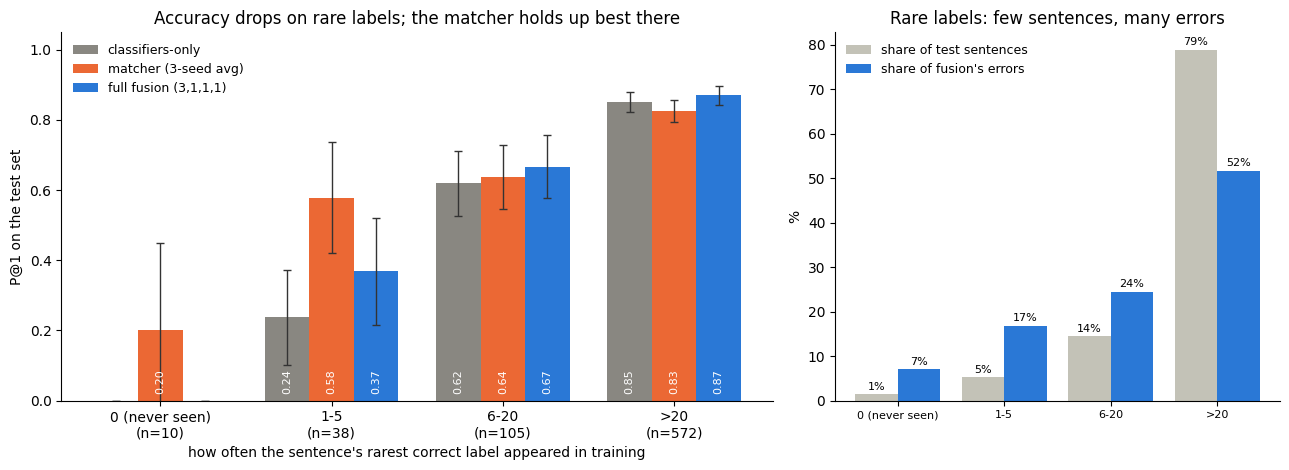

error counts per bucket: {'0 (never seen)': 10, '1-5': 24, '6-20': 35, '>20': 74} | saved: /content/drive/MyDrive/KDU/Thesis/run_match_1/label_rarity.png


In [ ]:
# Cell 14 - charts for the label-rarity result (run after Cell 13)
import matplotlib.pyplot as plt

show = {"classifiers-only": "#898781", "matcher (3-seed avg)": "#eb6834", "full fusion (3,1,1,1)": "#2a78d6"}
names_b = [b for b, _ in bins]
ns = np.array([int(m.sum()) for _, m in bins])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})

# left: P@1 per bucket, with a rough 95% noise bar (1.96*sqrt(p(1-p)/n))
w = 0.26
for j, (k, col) in enumerate(show.items()):
    p = np.array([hits[k][m].mean() for _, m in bins])
    err = 1.96 * np.sqrt(p * (1 - p) / ns)
    ax1.bar(np.arange(len(bins)) + (j - 1) * w, p, w, yerr=err, color=col, label=k,
            capsize=3, error_kw={"lw": 1, "ecolor": "#333"})
    for x, v in zip(np.arange(len(bins)) + (j - 1) * w, p):
        ax1.text(x, 0.02, f"{v:.2f}", ha="center", va="bottom", fontsize=8, color="white", rotation=90)
ax1.set_xticks(range(len(bins))); ax1.set_xticklabels([f"{b}\n(n={n})" for b, n in zip(names_b, ns)])
ax1.set_xlabel("how often the sentence's rarest correct label appeared in training")
ax1.set_ylabel("P@1 on the test set"); ax1.set_ylim(0, 1.05)
ax1.set_title("Accuracy drops on rare labels; the matcher holds up best there")
ax1.legend(loc="upper left", fontsize=9, frameon=False); ax1.spines[["top", "right"]].set_visible(False)

# right: where do the fusion's mistakes come from?
fus = hits["full fusion (3,1,1,1)"]
err_n = np.array([int((1 - fus[m]).sum()) for _, m in bins])
share_s, share_e = ns / ns.sum() * 100, err_n / err_n.sum() * 100
x = np.arange(len(bins))
ax2.bar(x - 0.2, share_s, 0.4, color="#c3c2b7", label="share of test sentences")
ax2.bar(x + 0.2, share_e, 0.4, color="#2a78d6", label="share of fusion's errors")
for xi, a, b_ in zip(x, share_s, share_e):
    ax2.text(xi - 0.2, a + 1, f"{a:.0f}%", ha="center", fontsize=8); ax2.text(xi + 0.2, b_ + 1, f"{b_:.0f}%", ha="center", fontsize=8)
ax2.set_xticks(x); ax2.set_xticklabels(names_b, fontsize=8); ax2.set_ylabel("%")
ax2.set_title("Rare labels: few sentences, many errors"); ax2.legend(fontsize=9, frameon=False)
ax2.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(f"{OUT_ROOT}/label_rarity.png", dpi=150, bbox_inches="tight")
plt.show()
print("error counts per bucket:", dict(zip(names_b, err_n.tolist())), "| saved:", f"{OUT_ROOT}/label_rarity.png")

In [ ]:
# Cell 15 - matcher ablation: train on 256-token descriptions instead of 128 (everything else unchanged), 3 seeds
# Needs a GPU, same session as Cells 2-3. Roughly as long as the earlier 3-seed run, a bit more.
for sd in (42, 43, 44):
    out = f"{OUT_ROOT}/ft20L256_s{sd}"
    if os.path.exists(f"{out}/metrics.json"):
        print("skip (already done):", out)
    else:
        train_matcher(BASE_MODEL, out, seed=sd, epochs=20, patience=4, batch_size=16, lr=2e-5, n_neg=64, scale=30.0,
                      label_max_len_train=256)

skip (already done): /content/drive/MyDrive/KDU/Thesis/run_match_1/ft20L256_s42


config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

... (4 outputs left out)

/tmp/ipykernel_1497/1140364382.py:79: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); tot += loss.item() * len(idx)


  epoch  1: train_loss=1.6812 dev P@1=0.5414 MRR@3=0.6432 R@5=0.7432 unseenR@5=0.750
  epoch  2: train_loss=0.8471 dev P@1=0.6606 MRR@3=0.7448 R@5=0.8060 unseenR@5=0.750
  epoch  3: train_loss=0.5093 dev P@1=0.7268 MRR@3=0.7889 R@5=0.8417 unseenR@5=0.750
  epoch  4: train_loss=0.3011 dev P@1=0.7119 MRR@3=0.7870 R@5=0.8502 unseenR@5=0.750
  epoch  5: train_loss=0.1912 dev P@1=0.7351 MRR@3=0.7988 R@5=0.8402 unseenR@5=0.750
  epoch  6: train_loss=0.1189 dev P@1=0.7517 MRR@3=0.8126 R@5=0.8459 unseenR@5=0.500
  epoch  7: train_loss=0.0869 dev P@1=0.7732 MRR@3=0.8325 R@5=0.8588 unseenR@5=0.750
  epoch  8: train_loss=0.0608 dev P@1=0.7848 MRR@3=0.8435 R@5=0.8716 unseenR@5=0.750
  epoch  9: train_loss=0.0409 dev P@1=0.7765 MRR@3=0.8386 R@5=0.8659 unseenR@5=0.750
  epoch 10: train_loss=0.0304 dev P@1=0.7781 MRR@3=0.8364 R@5=0.8702 unseenR@5=0.750
  epoch 11: train_loss=0.0287 dev P@1=0.7930 MRR@3=0.8441 R@5=0.8659 unseenR@5=0.500
  epoch 12: train_loss=0.0185 dev P@1=0.7848 MRR@3=0.8402 R@5=0.8

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[BAAI/bge-base-en-v1.5] seed=44 epochs<=20 bs=16 lr=2e-05 n_neg=64 scale=30.0 neg_pool=all
  epoch  1: train_loss=1.7164 dev P@1=0.5464 MRR@3=0.6443 R@5=0.7418 unseenR@5=0.750
  epoch  2: train_loss=0.8500 dev P@1=0.6656 MRR@3=0.7467 R@5=0.8160 unseenR@5=0.750
  epoch  3: train_loss=0.5102 dev P@1=0.7235 MRR@3=0.7867 R@5=0.8245 unseenR@5=0.750
  epoch  4: train_loss=0.3030 dev P@1=0.7185 MRR@3=0.7867 R@5=0.8345 unseenR@5=0.750
  epoch  5: train_loss=0.1894 dev P@1=0.7368 MRR@3=0.8035 R@5=0.8359 unseenR@5=0.750
  epoch  6: train_loss=0.1218 dev P@1=0.7517 MRR@3=0.8184 R@5=0.8502 unseenR@5=0.750
  epoch  7: train_loss=0.0877 dev P@1=0.7781 MRR@3=0.8328 R@5=0.8559 unseenR@5=0.750
  epoch  8: train_loss=0.0655 dev P@1=0.7798 MRR@3=0.8325 R@5=0.8559 unseenR@5=0.750
  epoch  9: train_loss=0.0463 dev P@1=0.7732 MRR@3=0.8273 R@5=0.8588 unseenR@5=0.750
  epoch 10: train_loss=0.0303 dev P@1=0.7864 MRR@3=0.8416 R@5=0.8602 unseenR@5=0.750
  epoch 11: train_loss=0.0283 dev P@1=0.7748 MRR@3=0.8308 R

In [7]:
# Cell 16 - old (128) vs new (256) matcher: overall, then by label rarity. DEV first, test is only a report.
# Run after Cells 7, 10 and 15 (needs Zs, W, others, rank_metrics, per_row).
seeds = (42, 43, 44)
dirs = {"old 128": lambda s: f"{OUT_ROOT}/ft20_s{s}", "new 256": lambda s: f"{OUT_ROOT}/ft20L256_s{s}"}

def avg_z(d, split):                       # z-scored average of the 3 seeds' scores, like M_avg in Cell 10
    return zrow(np.mean([np.load(f"{d(s)}/{split}_scores.npy") for s in seeds], axis=0))

Y = {"dev": Y_dev, "test": Y_test}; zi = {"dev": 0, "test": 1}
M, FU = {}, {}
for name, d in dirs.items():
    for sp in ("dev", "test"):
        M[name, sp] = avg_z(d, sp)
        FU[name, sp] = W["matcher"] * M[name, sp] + sum(W[n] * Zs[n][zi[sp]] for n in others)

# 1) per-seed matcher alone (test) and overall numbers
for name, d in dirs.items():
    p1 = [json.load(open(f"{d(s)}/metrics.json"))["test"]["P@1"] for s in seeds]
    print(f"{name}: matcher alone per seed, test P@1 mean {np.mean(p1):.3f} +- {np.std(p1, ddof=1):.3f}  (seeds: {[round(x, 3) for x in p1]})")
rows = []
for sp in ("dev", "test"):
    for name in dirs:
        for kind, S in (("matcher 3-seed avg", M[name, sp]), ("fusion (3,1,1,1)", FU[name, sp])):
            m = rank_metrics(S, Y[sp]); rows.append({"split": sp, "matcher": name, "system": kind,
                                                      **{k: round(m[k], 3) for k in ("P@1", "R@1", "MRR@3", "R@5")}})
print(pd.DataFrame(rows).to_string(index=False))

# 2) by label rarity (rarest correct label of each sentence, counted in TRAIN)
train_count = Y_train.sum(axis=0)
def bucket_masks(Yx):
    r = np.where(Yx.astype(bool), train_count[None, :], 10**9).min(axis=1)
    return [("0", r == 0), ("1-5", (r >= 1) & (r <= 5)), ("6-20", (r >= 6) & (r <= 20)), (">20", r > 20)]
for sp in ("dev", "test"):
    out = []
    for b, mask in bucket_masks(Y[sp]):
        row = {"bucket": b, "n": int(mask.sum())}
        for name in dirs:
            row[f"matcher {name}"] = round(float(per_row(M[name, sp], Y[sp])[0][mask].mean()), 3) if mask.any() else np.nan
        for name in dirs:
            row[f"fusion {name}"] = round(float(per_row(FU[name, sp], Y[sp])[0][mask].mean()), 3) if mask.any() else np.nan
        out.append(row)
    print(f"\nP@1 by rarity, {sp.upper()}:"); print(pd.DataFrame(out).to_string(index=False))

old 128: matcher alone per seed, test P@1 mean 0.756 +- 0.015  (seeds: [0.756, 0.771, 0.741])
new 256: matcher alone per seed, test P@1 mean 0.763 +- 0.008  (seeds: [0.768, 0.767, 0.754])
split matcher             system   P@1   R@1  MRR@3   R@5
  dev old 128 matcher 3-seed avg 0.785 0.676  0.844 0.862
  dev old 128   fusion (3,1,1,1) 0.823 0.709  0.873 0.907
  dev new 256 matcher 3-seed avg 0.810 0.698  0.858 0.869
  dev new 256   fusion (3,1,1,1) 0.823 0.709  0.873 0.912
 test old 128 matcher 3-seed avg 0.777 0.662  0.837 0.875
 test old 128   fusion (3,1,1,1) 0.803 0.684  0.856 0.917
 test new 256 matcher 3-seed avg 0.774 0.659  0.835 0.873
 test new 256   fusion (3,1,1,1) 0.800 0.682  0.855 0.912

P@1 by rarity, DEV:
bucket   n  matcher old 128  matcher new 256  fusion old 128  fusion new 256
     0   4            0.250            0.500           0.000           0.000
   1-5  34            0.471            0.500           0.382           0.382
  6-20  79            0.722           

In [8]:
# Cell 17 - gated fusion: give the matcher MORE weight when the classifiers are unsure. Rule chosen on DEV only.
# No GPU. Run after Cells 7, 10 and 16 (needs Zs, W, others, rank_metrics, per_row, Y_dev, Y_test, train/Y_train).
seeds = (42, 43, 44); zi = {"dev": 0, "test": 1}; Yd = {"dev": Y_dev, "test": Y_test}
def avg_z(root, split): return zrow(np.mean([np.load(f"{root}_s{s}/{split}_scores.npy") for s in seeds], axis=0))
C   = {sp: sum(Zs[n][zi[sp]] for n in others) for sp in zi}                 # classifiers only, equal weights (z-scores)
srt = {sp: np.sort(C[sp], axis=1) for sp in zi}
conf = {sp: srt[sp][:, -1] - srt[sp][:, -2] for sp in zi}                   # classifier confidence = top1 - top2 gap

def gated(M, sp, t, k):                     # matcher weight = 3 (as before) if classifiers are sure, k if not
    wm = np.where(conf[sp] >= t, W["matcher"], k)[:, None]
    return wm * M + C[sp]

qs = [0, .1, .2, .3, .4, .5, .6, .7, .8, .9]; ks = [3, 4, 5, 6, 8, 12]
for tag, root in (("128 (main result)", f"{OUT_ROOT}/ft20"), ("256 (secondary)", f"{OUT_ROOT}/ft20L256")):
    M = {sp: avg_z(root, sp) for sp in zi}
    best = None                                                             # q=0 means 'never boost' = the old fusion
    for q in qs:
        t = np.quantile(conf["dev"], q)
        for k in ks:
            if q == 0 and k != 3: continue
            m = rank_metrics(gated(M["dev"], "dev", t, k), Y_dev); key = (round(m["MRR@3"], 4), round(m["P@1"], 4))
            if best is None or key > best[0]: best = (key, q, t, k)          # strict '>' keeps the old fusion on ties
    _, q, t, k = best
    print(f"\n=== matcher {tag} ===")
    print(f"dev-chosen rule: boost matcher weight 3 -> {k} when classifier confidence is in the lowest {int(q*100)}% (gap < {t:.2f})")
    print(f"share of rows boosted: dev {np.mean(conf['dev'] < t):.0%}, test {np.mean(conf['test'] < t):.0%}")
    rows = []
    for sp in ("dev", "test"):
        for name, S in (("old fusion (3,1,1,1)", gated(M[sp], sp, -1e9, 3)), ("gated fusion", gated(M[sp], sp, t, k))):
            m = rank_metrics(S, Yd[sp]); rows.append({"split": sp, "system": name, **{a: round(m[a], 3) for a in ("P@1", "R@1", "MRR@3", "R@5")}})
    print(pd.DataFrame(rows).to_string(index=False))
    # by label rarity
    tc = Y_train.sum(axis=0)
    for sp in ("dev", "test"):
        r = np.where(Yd[sp].astype(bool), tc[None, :], 10**9).min(axis=1)
        out = []
        for b, mk in (("0", r == 0), ("1-5", (r >= 1) & (r <= 5)), ("6-20", (r >= 6) & (r <= 20)), (">20", r > 20)):
            h0 = per_row(gated(M[sp], sp, -1e9, 3), Yd[sp])[0]; h1 = per_row(gated(M[sp], sp, t, k), Yd[sp])[0]
            out.append({"bucket": b, "n": int(mk.sum()), "old fusion": round(float(h0[mk].mean()), 3) if mk.any() else np.nan,
                        "gated": round(float(h1[mk].mean()), 3) if mk.any() else np.nan})
        print(f"P@1 by rarity, {sp.upper()}:"); print(pd.DataFrame(out).to_string(index=False))
    # test: paired bootstrap, gated minus old
    h0, r0 = per_row(gated(M["test"], "test", -1e9, 3), Y_test); h1, r1 = per_row(gated(M["test"], "test", t, k), Y_test)
    rng = np.random.default_rng(0); d1, d2 = [], []
    for _ in range(1000):
        i = rng.integers(0, len(h0), len(h0)); d1.append((h1[i] - h0[i]).mean()); d2.append((r1[i] - r0[i]).mean())
    print(f"test, gated minus old: P@1 {h1.mean()-h0.mean():+.3f} [{np.percentile(d1,2.5):+.3f}, {np.percentile(d1,97.5):+.3f}] | "
          f"MRR@3 {r1.mean()-r0.mean():+.3f} [{np.percentile(d2,2.5):+.3f}, {np.percentile(d2,97.5):+.3f}]")


=== matcher 128 (main result) ===
dev-chosen rule: boost matcher weight 3 -> 5 when classifier confidence is in the lowest 40% (gap < 21.03)
share of rows boosted: dev 40%, test 42%
split               system   P@1   R@1  MRR@3   R@5
  dev old fusion (3,1,1,1) 0.823 0.709  0.873 0.907
  dev         gated fusion 0.829 0.715  0.878 0.906
 test old fusion (3,1,1,1) 0.803 0.684  0.856 0.917
 test         gated fusion 0.811 0.691  0.862 0.908
P@1 by rarity, DEV:
bucket   n  old fusion  gated
     0   4       0.000  0.250
   1-5  34       0.382  0.382
  6-20  79       0.810  0.810
   >20 487       0.862  0.869
P@1 by rarity, TEST:
bucket   n  old fusion  gated
     0  10       0.000  0.100
   1-5  38       0.368  0.447
  6-20 105       0.667  0.676
   >20 572       0.871  0.872
test, gated minus old: P@1 +0.008 [+0.001, +0.017] | MRR@3 +0.006 [+0.001, +0.011]

=== matcher 256 (secondary) ===
dev-chosen rule: boost matcher weight 3 -> 12 when classifier confidence is in the lowest 40% (gap <